# Implicit gradients through the iLQR solver

Often the optimal trajectory is just one component of a larger model. Examples are learning the
dynamics or cost parameters $\theta$ from data (inverse optimal control), or using a planner as a
layer in a neural network. Training such a model needs
$\partial \tau^\star(\theta) / \partial\theta$, where $\tau^\star = (x^\star, u^\star)$ is the
solution.

There are two ways to get these gradients:

- **Direct:** backpropagate through every iteration of the solver. This is exact for the unrolled
  computation, but memory grows with the number of iterations, and the gradient depends on the
  solver's path as well as its solution.
- **Implicit:** differentiate the optimality (KKT) conditions at the solution. By the implicit
  function theorem, the vector–Jacobian product is the solution of another LQR problem built
  from the Hessian of the Lagrangian. Its cost is about one extra LQR solve, independent of the
  number of solver iterations.

`diffilqrax.diff_ilqr.dilqr` implements the implicit approach as a `jax.custom_vjp`. It
returns $\tau^\star = [x_t, u_t]$, an array of shape `(T+1, n+m)` whose last row of $u$ is padded
with zeros. You can call `jax.grad` on it like any other JAX function.

In [1]:
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt

from diffilqrax.diff_ilqr import dilqr
from diffilqrax.ilqr import ilqr_solver
from diffilqrax.typs import System, ModelDims, iLQRParams, Theta

jax.config.update("jax_enable_x64", True)

## The problem

A small recurrent network $x_{t+1} = U_h \tanh(x_t) + W_h \tanh(u_t)$ must track a sine target
under a learnable state cost $Q$. The parameters are $\theta = (U_h, W_h, Q)$.

In [2]:
dims = ModelDims(n=6, m=2, horizon=60, dt=0.1)
k1, k2, k3 = jr.split(jr.PRNGKey(0), 3)
L = 0.5 * jr.normal(k3, (dims.n, dims.n)) / jnp.sqrt(dims.n)
theta = Theta(
    Uh=0.5 * jr.normal(k1, (dims.n, dims.n)) / jnp.sqrt(dims.n),
    Wh=0.5 * jr.normal(k2, (dims.n, dims.m)) / jnp.sqrt(dims.n),
    sigma=jnp.zeros(dims.n),
    Q=L @ L.T + 0.1 * jnp.eye(dims.n),
)
params = iLQRParams(x0=jnp.zeros(dims.n), theta=theta)


def cost(t, x, u, theta):
    err = x - jnp.sin(t / 5.0)
    return err @ theta.Q @ err + jnp.sum(u**2)


def costf(x, theta):
    return jnp.sum(x**2)


def dynamics(t, x, u, theta):
    return theta.Uh @ jnp.tanh(x) + theta.Wh @ jnp.tanh(u)


model = System(cost, costf, dynamics, dims)
Us_init = jnp.zeros((dims.horizon, dims.m))
solver_kwargs = dict(max_iter=100, kkt_tol=1e-10)

## A loss on the optimal trajectory

As an example outer objective, take the squared norm of the optimal trajectory,
$\mathcal{L}(\theta) = \lVert x^\star(\theta)\rVert^2 + \lVert u^\star(\theta)\rVert^2$. We
compare three gradients:

1. **implicit**: `dilqr` with the exact Lagrangian Hessian (the default, `exact_hessian=True`);
2. **direct**: `jax.grad` through every iteration of `ilqr_solver`;
3. **Gauss–Newton implicit**: `dilqr(..., exact_hessian=False)`, which drops the dynamics
   curvature $\lambda^\top \nabla^2 f$. It is cheaper, but exact only for linear dynamics.

In [3]:
def implicit_loss(theta, exact_hessian=True):
    tau = dilqr(model, iLQRParams(params.x0, theta), Us_init, exact_hessian=exact_hessian, **solver_kwargs)
    return jnp.sum(tau**2)


def direct_loss(theta):
    (Xs, Us, _), _, _ = ilqr_solver(model, iLQRParams(params.x0, theta), Us_init, **solver_kwargs)
    return jnp.sum(Xs**2) + jnp.sum(Us**2)


val_imp, g_imp = jax.value_and_grad(implicit_loss)(theta)
val_dir, g_dir = jax.value_and_grad(direct_loss)(theta)
g_gn = jax.grad(lambda th: implicit_loss(th, exact_hessian=False))(theta)
print(f"loss: implicit {float(val_imp):.8f}, direct {float(val_dir):.8f}")

loss: implicit 4.68615848, direct 4.68615848


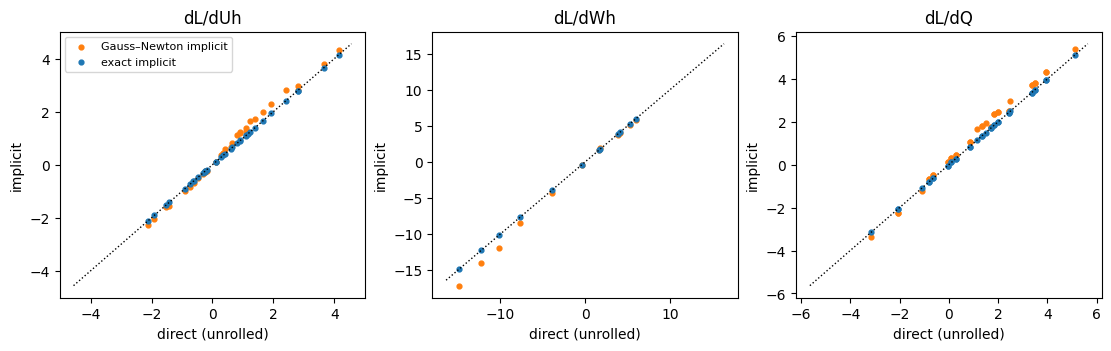

In [4]:
names = ["Uh", "Wh", "Q"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), layout="constrained")
for ax, name in zip(axes, names):
    d = getattr(g_dir, name).ravel()
    ax.scatter(d, getattr(g_gn, name).ravel(), s=12, c="C1", label="Gauss–Newton implicit")
    ax.scatter(d, getattr(g_imp, name).ravel(), s=12, c="C0", label="exact implicit")
    lim = jnp.abs(d).max() * 1.1
    ax.plot([-lim, lim], [-lim, lim], "k:", lw=1)
    ax.set(title=f"dL/d{name}", xlabel="direct (unrolled)", ylabel="implicit")
axes[0].legend(fontsize=8);

In [5]:
def rel_err(a, b):
    return float(jnp.linalg.norm(a - b) / jnp.linalg.norm(b))

for name in names:
    print(f"{name:3s} exact implicit vs direct: {rel_err(getattr(g_imp, name), getattr(g_dir, name)):.1e}   "
          f"Gauss–Newton vs direct: {rel_err(getattr(g_gn, name), getattr(g_dir, name)):.1e}")

Uh  exact implicit vs direct: 1.0e-10   Gauss–Newton vs direct: 1.3e-01
Wh  exact implicit vs direct: 9.5e-11   Gauss–Newton vs direct: 1.4e-01
Q   exact implicit vs direct: 4.9e-11   Gauss–Newton vs direct: 1.4e-01


The exact implicit gradient matches backpropagation through the converged solver to about
$10^{-10}$ relative error, the level of the solver tolerance, without storing the solver's
iterations. The Gauss–Newton variant is visibly biased
here because the dynamics are non-linear. For linear dynamics the two coincide.

## How to adapt

- **Learnable parameters:** anything inside `params.theta` (any pytree), and `params.x0`, receives
  gradients. Put whatever you want to learn there and read it in `cost`, `costf` and `dynamics`.
- **Outer loss:** `dilqr` returns `tau` of shape `(T+1, n+m)`. Slice `tau[:, :n]` for states and
  `tau[:-1, n:]` for inputs, and build any differentiable loss on them, for example a fit to
  observed trajectories.
- **Converge tightly:** implicit gradients assume the KKT conditions hold, so keep `kkt_tol` small
  (float64 is enabled by default).
- **LQR problems:** use `diffilqrax.diff_lqr.dlqr` with `LQRParams`. For long horizons on a
  GPU, use the parallel versions `diffilqrax.parallel_dilqr.pdilqr` and
  `diffilqrax.parallel_dlqr.pdlqr`.